<a href="https://colab.research.google.com/github/sidcodes2727/ML-labs/blob/main/SidMLLab8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import kagglehub

path = kagglehub.dataset_download("cherngs/heart-disease-cleveland-uci")
print(path)

Using Colab cache for faster access to the 'heart-disease-cleveland-uci' dataset.
/kaggle/input/heart-disease-cleveland-uci


In [ ]:
df = pd.read_csv('/kaggle/input/heart-disease-cleveland-uci/heart_cleveland_upload.csv')

print(df.shape)
print(df.columns)
print(df.isnull().sum())
print(df.head())
df

(297, 14)
Index(['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach',
       'exang', 'oldpeak', 'slope', 'ca', 'thal', 'condition'],
      dtype='object')
age          0
sex          0
cp           0
trestbps     0
chol         0
fbs          0
restecg      0
thalach      0
exang        0
oldpeak      0
slope        0
ca           0
thal         0
condition    0
dtype: int64
   age  sex  cp  trestbps  chol  fbs  restecg  thalach  exang  oldpeak  slope  \
0   69    1   0       160   234    1        2      131      0      0.1      1   
1   69    0   0       140   239    0        0      151      0      1.8      0   
2   66    0   0       150   226    0        0      114      0      2.6      2   
3   65    1   0       138   282    1        2      174      0      1.4      1   
4   64    1   0       110   211    0        2      144      1      1.8      1   

   ca  thal  condition  
0   1     0          0  
1   2     0          0  
2   0     0          0  
3   1     0       

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,condition
0,69,1,0,160,234,1,2,131,0,0.1,1,1,0,0
1,69,0,0,140,239,0,0,151,0,1.8,0,2,0,0
2,66,0,0,150,226,0,0,114,0,2.6,2,0,0,0
3,65,1,0,138,282,1,2,174,0,1.4,1,1,0,1
4,64,1,0,110,211,0,2,144,1,1.8,1,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
292,40,1,3,152,223,0,0,181,0,0.0,0,0,2,1
293,39,1,3,118,219,0,0,140,0,1.2,1,0,2,1
294,35,1,3,120,198,0,0,130,1,1.6,1,0,2,1
295,35,0,3,138,183,0,0,182,0,1.4,0,0,0,0


In [ ]:
df["condition"] = (df["condition"]>0).astype(int)
X = df.drop(columns=["condition"])
y = df["condition"]

In [ ]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)

In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

X_train = np.array(X_train)
X_test = np.array(X_test)
y_train = y_train.values
y_test = y_test.values

In [ ]:
def svm(X,y,lr=0.001,epochs=3000,C=1):

    m,n = X.shape
    y_svm = np.where(y==0,-1,1)
    # y=wx + b
    w = np.zeros(n)
    b = 0
    errors=[]
    # Loss = 1/2 * ||w||^2 + C Sum(max(0, 1-yi*f(xi)))
    for i in range(epochs):
        margin = y_svm*(np.dot(X,w)+b)
        misc = margin < 1

        dw = w-C*np.dot(X[misc].T,y_svm[misc])
        db = 0-C*np.sum(y_svm[misc])

        w = w-lr*dw
        b = b-lr*db

        margin = y_svm*(np.dot(X,w)+b)
        loss = 0.5*np.dot(w,w)+C*np.sum(np.maximum(0,1-margin))
        errors.append(loss)

    return w,b,errors

In [ ]:
w,b,errors = svm(X_train,y_train,lr=0.001,epochs=3000,C=1)

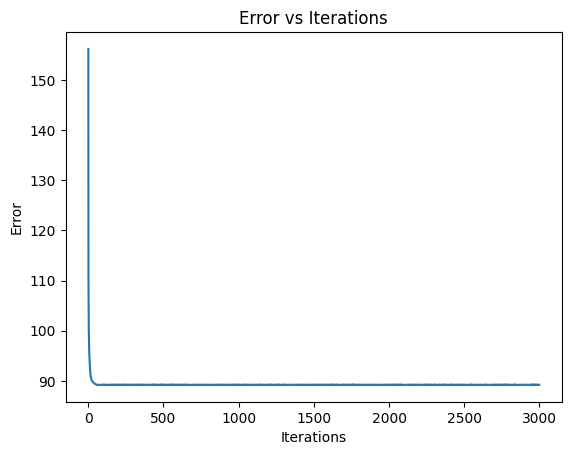

In [ ]:
plt.plot(errors)
plt.xlabel("Iterations")
plt.ylabel("Error")
plt.title("Error vs Iterations")
plt.show()

In [ ]:
def predict(X,w,b):
    z = np.dot(X,w)+b
    predictions = np.where(z>=0,1,0)

    return predictions

In [ ]:
from sklearn.metrics import classification_report,accuracy_score,confusion_matrix

y_pred = predict(X_test,w,b)

accuracy_svm = accuracy_score(y_test,y_pred)

print("Scratch Linear SVM Accuracy:",accuracy_svm)
print(classification_report(y_test,y_pred,zero_division=0))

Scratch Linear SVM Accuracy: 0.9
              precision    recall  f1-score   support

           0       0.84      1.00      0.91        32
           1       1.00      0.79      0.88        28

    accuracy                           0.90        60
   macro avg       0.92      0.89      0.90        60
weighted avg       0.92      0.90      0.90        60



In [ ]:
y_svm = np.where(y_train==0,-1,1)
margin = y_svm*(np.dot(X_train,w)+b)

idx = np.where(margin<=1)[0]
support_vectors = X_train[idx]

print("Number of Approximate Support Vectors:",len(idx))
print("Support Vectors:")
print(support_vectors)

Number of Approximate Support Vectors: 89
Support Vectors:
[[-0.22463889  0.6671746  -0.13898338 ... -0.94451701  2.34151803
  -0.89904015]
 [-1.57532177  0.6671746  -1.16832908 ...  0.62087132 -0.72444757
   0.15057815]
 [-1.35020796  0.6671746   0.89036231 ... -0.94451701 -0.72444757
   1.20019645]
 ...
 [ 1.01348708  0.6671746  -0.13898338 ... -0.94451701 -0.72444757
  -0.89904015]
 [ 1.3511578  -1.49885801 -0.13898338 ...  0.62087132 -0.72444757
   1.20019645]
 [ 0.45070255  0.6671746  -2.19767477 ... -0.94451701  1.3195295
  -0.89904015]]


In [ ]:
from sklearn.svm import SVC

model = SVC(kernel="linear",C=1)
model.fit(X_train,y_train)

y_pred_lib = model.predict(X_test)
accuracy_svm_lib = accuracy_score(y_test,y_pred_lib)

print("Library Linear SVM Accuracy:",accuracy_svm_lib)
print(classification_report(y_test,y_pred_lib,zero_division=0))

print("Number of Support Vectors:",len(model.support_vectors_))
print("Support Vectors:")
print(model.support_vectors_)

Library Linear SVM Accuracy: 0.9
              precision    recall  f1-score   support

           0       0.84      1.00      0.91        32
           1       1.00      0.79      0.88        28

    accuracy                           0.90        60
   macro avg       0.92      0.89      0.90        60
weighted avg       0.92      0.90      0.90        60

Number of Support Vectors: 100
Support Vectors:
[[-0.22463889  0.6671746  -0.13898338 ... -0.94451701  2.34151803
  -0.89904015]
 [-1.57532177  0.6671746  -1.16832908 ...  0.62087132 -0.72444757
   0.15057815]
 [-1.35020796  0.6671746   0.89036231 ... -0.94451701 -0.72444757
   1.20019645]
 ...
 [ 1.01348708  0.6671746  -0.13898338 ... -0.94451701 -0.72444757
  -0.89904015]
 [ 0.45070255  0.6671746  -2.19767477 ... -0.94451701  1.3195295
  -0.89904015]
 [-1.46276486  0.6671746   0.89036231 ...  0.62087132 -0.72444757
   0.15057815]]


In [ ]:
C= 1.0
gamma= 0.01
eph= 10000
lr= 0.001

y_train_svm= np.where(y_train == 0, -1.0, 1.0)
m = X_train.shape[0]

#J= sum(a) - 0.5 * sumi sumj(ai*aj*yi*yj*K(xi, xj))
def rbf(x1,x2,gamma):
    return np.exp(-gamma*np.sum((x1-x2)**2))

kern = np.zeros((m, m))
for i in range(m):
    for j in range(m):
        kern[i][j] = rbf(X_train[i], X_train[j], gamma)

Q= np.zeros((m, m))
for i in range(m):
    for j in range(m):
        Q[i][j] = y_train_svm[i]*y_train_svm[j]*kern[i][j]

alphas = np.zeros(m)

for e in range(eph):
    dQ= np.ones(m) - 0.5*np.dot(Q,alphas)
    alphas=alphas + lr*dQ
    alphas=np.clip(alphas,0,C)

    obj = np.sum(alphas) - 0.5*np.dot(alphas,np.dot(Q,alphas))


supports= np.where(alphas>0)[0]
X_support= X_train[supports]
y_support= y_train_svm[supports]
alpha_support= alphas[supports]

b= 0
for i in supports:
    if 0<alphas[i]<C:
        S= np.sum(alpha_support*y_support*np.array([rbf(a, X_train[i], gamma) for a in X_support]))
        b= y_train_svm[i] - S
        break

print("Number of support vectors:", len(supports))
print("Bias:", b)


Number of support vectors: 163
Bias: 0.9729104516831395


In [ ]:
def predict_dual_kernel(X):
    predictions = []
    for x in X:
        out = np.sum(alpha_support * y_support *np.array([rbf(sv,x,gamma) for sv in X_support]))+b
        predictions.append(1 if out >= 0 else 0)
    return np.array(predictions)

y_pred_dual_kernel = predict_dual_kernel(X_test)
accuracy_dual_kernel = accuracy_score(y_test, y_pred_dual_kernel)

print("Dual RBF Kernel SVM Accuracy:", accuracy_dual_kernel)
print(classification_report(y_test, y_pred_dual_kernel, zero_division=0))
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_dual_kernel))


Dual RBF Kernel SVM Accuracy: 0.8333333333333334
              precision    recall  f1-score   support

           0       0.84      0.84      0.84        32
           1       0.82      0.82      0.82        28

    accuracy                           0.83        60
   macro avg       0.83      0.83      0.83        60
weighted avg       0.83      0.83      0.83        60

Confusion Matrix:
[[27  5]
 [ 5 23]]


In [ ]:
from sklearn.svm import SVC

model_rbf = SVC(kernel="rbf", C=1, gamma=0.01)
model_rbf.fit(X_train, y_train)

y_pred_rbf = model_rbf.predict(X_test)
accuracy_svm_rbf = accuracy_score(y_test, y_pred_rbf)

print("Library RBF SVM Accuracy:", accuracy_svm_rbf)
print(classification_report(y_test, y_pred_rbf, zero_division=0))

print("Number of Support Vectors:", len(model_rbf.support_vectors_))
print("Support Vectors:")
print(model_rbf.support_vectors_)

Library RBF SVM Accuracy: 0.9
              precision    recall  f1-score   support

           0       0.84      1.00      0.91        32
           1       1.00      0.79      0.88        28

    accuracy                           0.90        60
   macro avg       0.92      0.89      0.90        60
weighted avg       0.92      0.90      0.90        60

Number of Support Vectors: 133
Support Vectors:
[[-0.22463889  0.6671746  -0.13898338 ... -0.94451701  2.34151803
  -0.89904015]
 [-1.57532177  0.6671746  -1.16832908 ...  0.62087132 -0.72444757
   0.15057815]
 [-1.35020796  0.6671746   0.89036231 ... -0.94451701 -0.72444757
   1.20019645]
 ...
 [ 0.45070255  0.6671746  -2.19767477 ... -0.94451701  1.3195295
  -0.89904015]
 [-1.46276486  0.6671746   0.89036231 ...  0.62087132 -0.72444757
   0.15057815]
 [-0.56230961  0.6671746   0.89036231 ...  0.62087132 -0.72444757
   1.20019645]]


In [ ]:
from sklearn.neural_network import MLPClassifier

model_nn = MLPClassifier(hidden_layer_sizes=(16,),max_iter=2000,random_state=42,early_stopping=False)
model_nn.fit(X_train,y_train)

y_pred_nn = model_nn.predict(X_test)
accuracy_nn = accuracy_score(y_test,y_pred_nn)

print("Neural Network Accuracy:",accuracy_nn)
print(classification_report(y_test,y_pred_nn,zero_division=0))
print(confusion_matrix(y_test,y_pred_nn))

Neural Network Accuracy: 0.8333333333333334
              precision    recall  f1-score   support

           0       0.82      0.88      0.85        32
           1       0.85      0.79      0.81        28

    accuracy                           0.83        60
   macro avg       0.83      0.83      0.83        60
weighted avg       0.83      0.83      0.83        60

[[28  4]
 [ 6 22]]


In [ ]:
results = pd.DataFrame({
    "Model": ["Scratch Primal Linear SVM","Dual RBF Kernel SVM (from scratch)","Library Linear SVM", "Library rbf SVM", "Neural Network"],
    "Accuracy": [accuracy_svm,accuracy_dual_kernel,accuracy_svm_lib,accuracy_svm_rbf,accuracy_nn]
})

print(results)

                                Model  Accuracy
0           Scratch Primal Linear SVM  0.900000
1  Dual RBF Kernel SVM (from scratch)  0.833333
2                  Library Linear SVM  0.900000
3                     Library rbf SVM  0.900000
4                      Neural Network  0.833333
